### Recovering the symbol from a travelling fKdV waves

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [ ]:
from solvers.spectral import fKdVNewton
from solvers.pde import fKdV
from solvers.lsm import LSM
from solvers.help import *

from waves.waveGen import KdVPacket

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
P           = 4* np.pi
amps = np.linspace(0.1,1,5)
means = np.zeros_like(amps)

N           = 2**6

dt = 5e-3
T = 3

In [4]:
x = np.linspace(0,P,N)

In [5]:
kdvp = KdVPacket(P=P,N=N,amp_list=amps, mean_list=means, dt = dt, T= T)
H = kdvp.mainloop()

In [ ]:
lsm = LSM(eta_list=H, dt = dt, P = P)
X = lsm.lsm()

array([[            nan+0.00000000e+00j,             nan+0.00000000e+00j],
       [ 9.55151179e-01+9.76175060e-07j,  4.98332051e-01-4.83768834e-07j],
       [ 8.30593586e-01-1.98695072e-07j,  4.98304841e-01+7.98193748e-08j],
       [ 6.23024753e-01+6.29045288e-06j,  4.98259229e-01-2.17726434e-06j],
       [ 3.32519762e-01+3.01751464e-06j,  4.98185114e-01-8.57860071e-07j],
       [-4.07970433e-02-1.56432887e-05j,  4.98072318e-01+3.55889778e-06j],
       [-4.96844913e-01-4.50772849e-05j,  4.97931899e-01+8.41644974e-06j],
       [-1.03519087e+00-6.63311473e-05j,  4.97719788e-01+1.02293930e-05j],
       [-1.65575679e+00-2.01093244e-04j,  4.97473762e-01+2.59265261e-05j],
       [-2.35736053e+00-3.00688503e-04j,  4.97099711e-01+3.26806848e-05j],
       [-3.13710789e+00-2.78633876e-04j,  4.96410915e-01+2.57422757e-05j],
       [-4.00669975e+00-3.10129948e-03j,  4.96511323e-01+2.47080143e-04j],
       [-4.93788183e+00+9.26741212e-03j,  4.95185654e-01-6.40643415e-04j],
       [-5.94071200e+00+6

In [7]:
ell, n = lsm.fit_symbol()
print(fit_table(ell,n,part='real'))


          ξ^3       ξ^2       ξ^1       ξ^0
ell -0.000897 -0.037913  0.098290 -3.850893
n    0.000009 -0.001665 -0.000939  0.555890


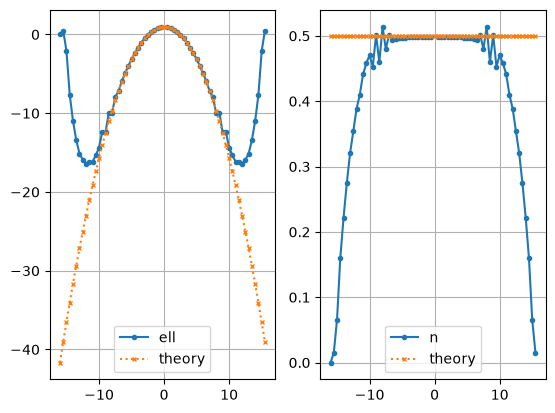

In [8]:
lsm.plot_symbol_fit()